In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv("fetch_california_housing.csv")

In [3]:
df.head(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41,6.984127,1.023810,322,2.555556,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,1.081081,565,2.181467,37.85,-122.25,3.422


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  int64  
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  int64  
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(7), int64(2)
memory usage: 1.4 MB


In [12]:
df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
target        0
dtype: int64

In [13]:
df.duplicated().sum()  

np.int64(0)

In [14]:
df.iloc[:,1:]

,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,41,6.984127,1.023810,322,2.555556,37.88,-122.23,4.526
1,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,52,6.281853,1.081081,565,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...
20635,25,5.045455,1.133333,845,2.560606,39.48,-121.09,0.781
20636,18,6.114035,1.315789,356,3.122807,39.49,-121.21,0.771
20637,17,5.205543,1.120092,1007,2.325635,39.43,-121.22,0.923
20638,18,5.329513,1.171920,741,2.123209,39.43,-121.32,0.847


In [15]:
X = df.drop(columns=['HouseAge'])
y = df['HouseAge']

In [16]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=24,test_size=0.2)

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error,accuracy_score
model=LinearRegression()
model.fit(X_train,y_train)
predit=model.predict(X_test)
print("R2:", r2_score(y_test, predit))
print("MAE:", mean_absolute_error(y_test, predit))

R2: 0.20086462871197786
MAE: 9.205589865187589


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error,accuracy_score
model=RandomForestRegressor(random_state=42,n_estimators=200,max_depth=20)
model.fit(X_train,y_train)
pred=model.predict(X_test)
print("R2:", r2_score(y_test, pred))
print("MAE:", mean_absolute_error(y_test, pred))



R2: 0.6051406215570962
MAE: 6.000636685074491


In [20]:
   import pandas as pd
   print(pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False))

Longitude     0.257855
Latitude      0.177789
Population    0.156414
AveRooms      0.104604
AveOccup      0.092093
MedInc        0.079705
target        0.071226
AveBedrms     0.060313
dtype: float64


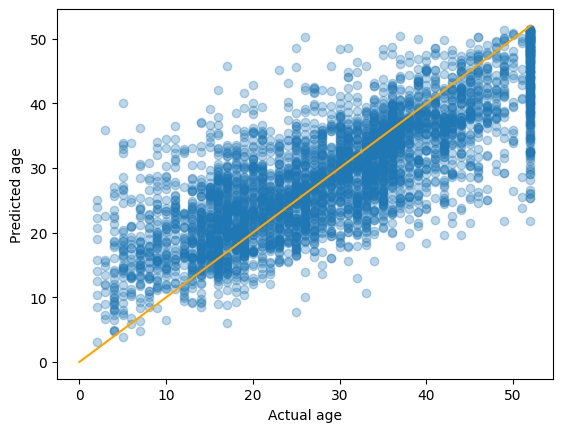

In [21]:
import matplotlib.pyplot as plt

plt.scatter(y_test, pred, alpha=0.3)
plt.plot([0, 52], [0, 52], color="orange")
plt.xlabel("Actual age")
plt.ylabel("Predicted age")
plt.show()